In [1]:
from typing import Annotated

from langchain_community.tools import WikipediaQueryRun
from langchain_community.utilities import WikipediaAPIWrapper
from datetime import datetime
from langchain.tools import tool

# Define a tool that searches Wikipedia
_wikipedia_query = WikipediaQueryRun(api_wrapper=WikipediaAPIWrapper())

@tool("wikipedia")
def wikipedia_tool(query: str) -> str:
    """Search Wikipedia for the given query and return a summary."""
    try:
        return _wikipedia_query.invoke(query)
    except Exception as exc:
        return f"Wikipedia lookup failed ({exc}). Answer from your own knowledge instead."

# Define a new tool that returns the current datetime
@tool("current_datetime")
def datetime_tool() -> str:
    """Returns the current datetime."""
    return datetime.now().isoformat()

/var/folders/6d/pc226b2d5kxgdffc0fkf5tpc0000gp/T/ipykernel_30414/3067699577.py:3: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.tools import WikipediaQueryRun


In [2]:
from langchain.agents import create_agent
from langchain_core.messages import BaseMessage, HumanMessage
from langchain_openai import ChatOpenAI

def create_worker_agent(llm: ChatOpenAI, system_prompt: str, tools: list):
    # Each worker node will be given a name and some tools.
    return create_agent(
        model=llm,
        tools=tools,
        system_prompt=system_prompt,
    )

def agent_node(state, agent, name):
    result = agent.invoke(state)
    return {"messages": [HumanMessage(content=result["messages"][-1].content, name=name)]}

In [3]:
from langchain_core.prompts import ChatPromptTemplate, MessagesPlaceholder

members = ["Researcher", "CurrentTime"]
system_prompt = (
    "You are a supervisor tasked with managing a conversation between the"
    " following workers:  {members}. Given the following user request,"
    " respond with the worker to act next. Each worker will perform a"
    " task and respond with their results and status. When finished,"
    " respond with FINISH."
)
# Our team supervisor is an LLM node. It just picks the next agent to process and decides when the work is completed
options = ["FINISH"] + members

# Using structured output can make routing easier for us
function_def = {
    "name": "route",
    "description": "Select the next role.",
    "parameters": {
        "title": "routeSchema",
        "type": "object",
        "properties": {
            "next": {
                "title": "Next",
                "anyOf": [
                    {"enum": options},
                ],
            }
        },
        "required": ["next"],
    },
}

# Create the prompt using ChatPromptTemplate
prompt = ChatPromptTemplate.from_messages(
    [
        ("system", system_prompt),
        MessagesPlaceholder(variable_name="messages"),
        (
            "system",
            "Given the conversation above, who should act next?"
            " Or should we FINISH? Select one of: {options}",
        ),
    ]
).partial(options=str(options), members=", ".join(members))

llm = ChatOpenAI(model="gpt-4o")

# Construction of the chain for the supervisor agent
supervisor_chain = prompt | llm.with_structured_output(function_def)

In [4]:
import functools
import operator
from typing import Sequence, TypedDict
from langchain_core.prompts import ChatPromptTemplate, MessagesPlaceholder
from langgraph.graph import END, StateGraph, START

# The agent state is the input to each node in the graph
class AgentState(TypedDict):
    # The annotation tells the graph that new messages will always be added to the current states
    messages: Annotated[Sequence[BaseMessage], operator.add]
    # The 'next' field indicates where to route to next
    next: str

# Add the research agent using the create_agent helper function
research_agent = create_worker_agent(llm, "You are a web researcher.", [wikipedia_tool])
research_node = functools.partial(agent_node, agent=research_agent, name="Researcher")

# Add the time agent using the create_agent helper function
currenttime_agent = create_worker_agent(llm, "You can tell the current time.", [datetime_tool])
currenttime_node = functools.partial(agent_node, agent=currenttime_agent, name = "CurrentTime")

workflow = StateGraph(AgentState)

# Add a "chatbot" node. Nodes represent units of work. They are typically regular python functions.
workflow.add_node("Researcher", research_node)
workflow.add_node("CurrentTime", currenttime_node)
workflow.add_node("supervisor", supervisor_chain)

# We want our workers to ALWAYS "report back" to the supervisor when done
for member in members:
    workflow.add_edge(member, "supervisor")

# Conditional edges usually contain "if" statements to route to different nodes depending on the current graph state.
# These functions receive the current graph state and return a string or list of strings indicating which node(s) to call next.
conditional_map = {k: k for k in members}
conditional_map["FINISH"] = END
workflow.add_conditional_edges("supervisor", lambda x: x["next"], conditional_map)

# Add an entry point. This tells our graph where to start its work each time we run it.
workflow.add_edge(START, "supervisor")

# To be able to run our graph, call "compile()" on the graph builder. This creates a "CompiledGraph" we can use invoke on our state.
graph_2 = workflow.compile()

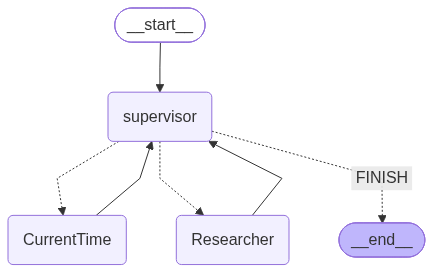

In [5]:
from IPython.display import Image, display
display(Image(graph_2.get_graph().draw_mermaid_png()))

In [6]:
from langfuse import propagate_attributes
from langfuse.langchain import CallbackHandler

# Initialize Langfuse CallbackHandler for Langchain (tracing)
langfuse_handler = CallbackHandler()

with propagate_attributes(
    trace_name="LangGraph Research Agent",
    user_id="user-1233",
    session_id="session-abcd",
    tags=["langgraph", "cookbook", "multi-agent", "research"],
    metadata={"example": "multi-agent", "route": "research"},
):
    for s in graph_2.stream(
        {"messages": [HumanMessage(content="How does photosynthesis work?")]},
        config={
            "callbacks": [langfuse_handler],
            "run_name": "answer-research-question",
        },
    ):
        print(s)
        print("----")

{'supervisor': {'next': 'Researcher'}}
----


/Users/pratyush.karna/personal/learn-ai/open_telemetry_and_evaluations/projects_basic_langfuse/.venv/lib/python3.13/site-packages/wikipedia/wikipedia.py:389: GuessedAtParserWarning: No parser was explicitly specified, so I'm using the best available HTML parser for this system ("html.parser"). This usually isn't a problem, but if you run this code on another system, or in a different virtual environment, it may use a different parser and behave differently.

The code that caused this warning is on line 389 of the file /Users/pratyush.karna/personal/learn-ai/open_telemetry_and_evaluations/projects_basic_langfuse/.venv/lib/python3.13/site-packages/wikipedia/wikipedia.py. To get rid of this warning, pass the additional argument 'features="html.parser"' to the BeautifulSoup constructor.

  lis = BeautifulSoup(html).find_all('li')


{'Researcher': {'messages': [HumanMessage(content="Photosynthesis is a biological process by which autotrophic organisms, such as most plants, algae, and cyanobacteria, convert light energy, usually from the sun, into chemical energy to fuel their metabolism. This process primarily refers to oxygenic photosynthesis, which releases oxygen as a byproduct. Here's a brief overview of how it works:\n\n1. **Energy Absorption**: Light energy is absorbed by reaction centers in the cells that contain photosynthetic pigments like chlorophyll. In plants, these pigments are located inside chloroplasts, abundant in leaf cells.\n\n2. **Light-Dependent Reactions**: The absorbed energy is used to split water molecules, releasing oxygen gas as a byproduct. This process also produces two important energy-carrying molecules: reduced nicotinamide adenine dinucleotide phosphate (NADPH) and adenosine triphosphate (ATP).\n\n3. **Calvin Cycle (Light-Independent Reactions)**: Using the ATP and NADPH produced, 

In [7]:
with propagate_attributes(
    trace_name="LangGraph Time Agent",
    user_id="user-1233",
    session_id="session-abcd",
    tags=["langgraph", "cookbook", "multi-agent", "tool-calling"],
    metadata={"example": "multi-agent", "route": "current-time"},
):
    for s in graph_2.stream(
        {"messages": [HumanMessage(content="What time is it?")]},
        config={
            "callbacks": [langfuse_handler],
            "run_name": "answer-time-question",
        },
    ):
        print(s)
        print("----")

{'supervisor': {'next': 'CurrentTime'}}
----
{'CurrentTime': {'messages': [HumanMessage(content='The current time is 11:15 PM on September 27, 2026.', additional_kwargs={}, response_metadata={}, name='CurrentTime')]}}
----
{'supervisor': {'next': 'FINISH'}}
----


In [8]:
# another way 
result = graph_2.invoke(
    {"messages": [HumanMessage(content="What time is it?")]},
    config={
        "callbacks": [langfuse_handler],
        "run_name": "answer-time-question",
        "metadata": {
            "langfuse_session_id": "session-abcd",
            "langfuse_user_id": "user-12334",
            "langfuse_tags": ["langgraph", "cookbook", "multi-agent", "tool-calling"],
            "example": "multi-agent",
            "route": "current-time",
        },
    },
)
print(result)


{'messages': [HumanMessage(content='What time is it?', additional_kwargs={}, response_metadata={}, id='1aca473b-00fe-4b86-92a9-166e851652ec'), HumanMessage(content='The current time is 11:27 PM on September 27, 2026.', additional_kwargs={}, response_metadata={}, name='CurrentTime')], 'next': 'FINISH'}


In [ ]:
# or
for s in graph_2.stream(
    {"messages": [HumanMessage(content="What time is it?")]},
    config={
        "callbacks": [langfuse_handler],
        "run_name": "answer-time-question",
        "metadata": {
            "langfuse_session_id": "session-abcd",
            "langfuse_user_id": "user-1233",
            "langfuse_tags": ["langgraph", "cookbook", "multi-agent", "tool-calling"],
            "example": "multi-agent",
            "route": "current-time",
        },
    },
):
    print(s)
    print("----")